# Thông tin nhóm

| | Họ và tên | MSSV | Lớp |
|:---:|:---:|:---:|:---:|
| Thành viên 1 |Phan Anh Đức| 24120500|24CNTN|
| Thành viên 2 |Trịnh Văn Thành|24120225|24CNTN|

In [1]:
# Import các thư viện cần thiết
import matplotlib.pyplot as plt
import numpy as np

#### Câu 2a: Kỳ vọng số lần Drogon ở nhà

**Lập luận toán học:**
Drogon bắt đầu hành trình tại một vị trí ngẫu nhiên tuân theo phân phối dừng $s$. Theo tính chất của xích Markov, nếu phân phối ban đầu $\pi_0 = s$, thì phân phối tại mọi thời điểm $n \ge 0$ cũng sẽ chính là phân phối dừng ($\pi_n = s$). 

Do đó, xác suất để Drogon ở nhà (trạng thái 0) tại **bất kỳ** thời điểm $n$ nào cũng luôn bằng $s_0$. 
Gọi $N_0$ là biến ngẫu nhiên đếm số lần Drogon ở nhà từ thời điểm $0$ đến $24$. Ta có thể biểu diễn $N_0$ dưới dạng tổng các biến chỉ thị $I_n$ (với $I_n = 1$ nếu $X_n = 0$, ngược lại bằng $0$).
Theo tính chất tuyến tính của kỳ vọng, kỳ vọng số lần Drogon ở nhà là:
$$
E[N_0] = E\left[\sum_{n=0}^{24} I_n\right] = \sum_{n=0}^{24} E[I_n] = \sum_{n=0}^{24} P(X_n = 0) = \sum_{n=0}^{24} s_0 = 25 \times s_0
$$

In [2]:
# --- CÂU 2(a) ---

def expected_drogon_home_visits(s0):
    """
    Hàm tính kỳ vọng số lần Drogon ở nhà từ thời điểm 0 đến thời điểm 24.
    Đầu vào: s0 (xác suất dừng tại trạng thái nhà)
    Đầu ra: Kỳ vọng số lần ở nhà
    """
    # Dãy X_0, X_1, ..., X_24 có tổng cộng 25 thời điểm (từ 0 đến 24)
    num_steps = 25
    
    # Tính kỳ vọng dựa trên công thức toán học đã chứng minh: E = 25 * s0
    expected_visits = num_steps * s0
    
    return expected_visits

# In ra màn hình kết quả tổng quát theo yêu cầu của đề bài
print("--- KẾT QUẢ CÂU 2a ---")
print("Công thức tổng quát tính kỳ vọng số lần Drogon ở nhà (theo s0) là: E = 25 * s0")

# (Tùy chọn) Chạy thử nghiệm hàm với một giá trị s0 giả định để kiểm tra
s0_test = 0.2
print(f"Ví dụ minh họa: Nếu s0 = {s0_test}, kỳ vọng số lần ở nhà là: {expected_drogon_home_visits(s0_test)}")

--- KẾT QUẢ CÂU 2a ---
Công thức tổng quát tính kỳ vọng số lần Drogon ở nhà (theo s0) là: E = 25 * s0
Ví dụ minh họa: Nếu s0 = 0.2, kỳ vọng số lần ở nhà là: 5.0


**Công thức tổng quát tính kỳ vọng (Câu 2a):**

Dựa trên lập luận toán học, ta có công thức tổng quát biểu diễn kỳ vọng số lần Drogon ở nhà từ thời điểm $0$ đến $24$ theo tham số $s_0$ là:

$$
E[N_0] = 25 \times s_0
$$

**Trong đó:**
* $E[N_0]$: Kỳ vọng số lần Drogon ở trạng thái nhà (trạng thái 0) trong 25 bước ($t=0$ đến $t=24$).
* $25$: Tổng số thời điểm được xét trong dãy $X_0, X_1, \dots, X_{24}$.
* $s_0$: Xác suất phân phối dừng tại trạng thái nhà ($P(X_n = 0) = s_0$).

### Câu 2b: Tính chất của dãy $W_n$

**Ý tưởng thực hiện và Lập luận toán học:**
Để xác định dãy $W_0, W_1, \dots$ có phải là một chuỗi Markov hay không, ta cần xem xét tính chất của vector vị trí $(X_n, Y_n, Z_n)$.

Theo giả thiết, $X_n, Y_n, Z_n$ là ba chuỗi Markov hoạt động **độc lập** với nhau. Do đó, xác suất để vector vị trí chuyển sang trạng thái mới tại thời điểm $n+1$ chỉ phụ thuộc vào trạng thái của chúng tại thời điểm $n$, tuân theo quy tắc nhân xác suất độc lập:
$$
P(X_{n+1}, Y_{n+1}, Z_{n+1} | X_n, Y_n, Z_n, X_{n-1}, Y_{n-1}, Z_{n-1}, \dots)
$$
$$
= P(X_{n+1} | X_n) \times P(Y_{n+1} | Y_n) \times P(Z_{n+1} | Z_n)
$$
Biểu thức trên chứng minh rằng vector không gian 3 chiều $(X_n, Y_n, Z_n)$ thỏa mãn tính chất Markov (trạng thái tương lai chỉ phụ thuộc vào hiện tại, không phụ thuộc vào quá khứ).

Đại lượng $W_n$ thực chất chỉ là một phép **ánh xạ một-một (song ánh)**, dùng để mã hóa vector 3 chiều $(X_n, Y_n, Z_n)$ thành một số nguyên 1 chiều (từ $1$ đến $M^3$). Vì việc đổi tên/mã hóa các trạng thái bằng một song ánh không làm thay đổi bản chất luân chuyển xác suất của hệ thống, nên $W_n$ kế thừa trọn vẹn tính chất Markov của hệ thống gốc.

Để minh họa cho phép ánh xạ song ánh này, ta có thể xây dựng một hàm mã hóa và giải mã tọa độ trong Python để chứng minh rằng với mọi vector $(X_n, Y_n, Z_n)$, luôn tồn tại duy nhất một giá trị $W_n$ và ngược lại.

In [3]:
# --- CÂU 2(b): MINH HỌA PHÉP ÁNH XẠ SONG ÁNH (BIJECTION) ---

def encode_W(x, y, z, M):
    """
    Hàm mã hóa vector vị trí (x, y, z) thành số nguyên W (từ 1 đến M^3).
    Dựa trên hệ cơ số M.
    """
    # Công thức chuyển đổi từ tọa độ 3D sang chỉ số 1D (bắt đầu từ 1)
    w = (x * (M ** 2)) + (y * M) + z + 1
    return w

def decode_W(w, M):
    """
    Hàm giải mã số nguyên W trở lại thành vector vị trí (x, y, z).
    """
    # Đưa W về index bắt đầu từ 0
    w_index = w - 1
    
    x = w_index // (M ** 2)
    w_index = w_index % (M ** 2)
    
    y = w_index // M
    z = w_index % M
    
    return (x, y, z)

# Kiểm thử với M = 2 theo ví dụ của đề bài
M_test = 2
print(f"--- KIỂM THỬ ÁNH XẠ VỚI M = {M_test} ---")
states = [
    (0, 0, 0), (0, 0, 1), (0, 1, 0), (0, 1, 1),
    (1, 0, 0), (1, 0, 1), (1, 1, 0), (1, 1, 1)
]

for state in states:
    w_val = encode_W(state[0], state[1], state[2], M_test)
    decoded_state = decode_W(w_val, M_test)
    print(f"Vector {state}  --->  Mã hóa thành W = {w_val}  --->  Giải mã về {decoded_state}")

--- KIỂM THỬ ÁNH XẠ VỚI M = 2 ---
Vector (0, 0, 0)  --->  Mã hóa thành W = 1  --->  Giải mã về (0, 0, 0)
Vector (0, 0, 1)  --->  Mã hóa thành W = 2  --->  Giải mã về (0, 0, 1)
Vector (0, 1, 0)  --->  Mã hóa thành W = 3  --->  Giải mã về (0, 1, 0)
Vector (0, 1, 1)  --->  Mã hóa thành W = 4  --->  Giải mã về (0, 1, 1)
Vector (1, 0, 0)  --->  Mã hóa thành W = 5  --->  Giải mã về (1, 0, 0)
Vector (1, 0, 1)  --->  Mã hóa thành W = 6  --->  Giải mã về (1, 0, 1)
Vector (1, 1, 0)  --->  Mã hóa thành W = 7  --->  Giải mã về (1, 1, 0)
Vector (1, 1, 1)  --->  Mã hóa thành W = 8  --->  Giải mã về (1, 1, 1)


**Tổng hợp kết luận 2b:**

Thông qua kết quả chạy đoạn mã trên, ta thấy phép biến đổi tọa độ từ $(X_n, Y_n, Z_n)$ sang $W_n$ là một phép **song ánh hoàn hảo**. Với $M=2$, $8$ trạng thái vector được ánh xạ chính xác thành các số nguyên từ $1$ đến $8$ mà không có sự trùng lặp hay mất mát thông tin.

Vì hệ thống gốc $(X_n, Y_n, Z_n)$ thỏa mãn tính chất Markov (do sự độc lập của 3 con rồng), và quá trình chuyển đổi sang $W_n$ chỉ là việc gán nhãn lại trạng thái, ta kết luận chắc chắn: 

Dãy $W_0, W_1, \dots$ **LÀ MỘT CHUỖI MARKOV**.

### Câu 2c: Thời gian kỳ vọng để 3 con rồng cùng về nhà

**Ý tưởng thực hiện và Lập luận toán học:**
Bài toán yêu cầu tìm "thời gian kỳ vọng" để hệ thống quay trở lại trạng thái ban đầu (cả 3 con rồng cùng ở nhà). Trong lý thuyết Xích Markov, đại lượng này được gọi là **Thời gian trở lại trung bình (Mean Return Time)**.

Định lý cơ bản của Xích Markov phát biểu rằng: nếu trạng thái $i$ có xác suất dừng là $\pi_i$, thì thời gian kỳ vọng để chuỗi quay trở lại trạng thái $i$ lần nữa bằng nghịch đảo của xác suất dừng tại trạng thái đó. Công thức:

$$
E[T_i^+] = \frac{1}{\pi_i}
$$

Dựa trên kết quả chứng minh ở câu 2b, vector vị trí $(X_n, Y_n, Z_n)$ là một chuỗi Markov. Gọi trạng thái "cả 3 con rồng ở nhà" là vector $(0, 0, 0)$.

Vì 3 con rồng di chuyển hoàn toàn độc lập với nhau và có cùng phân phối dừng là $s$, xác suất dừng tại trạng thái $(0, 0, 0)$ sẽ bằng tích các xác suất dừng độc lập của từng con rồng tại trạng thái $0$:

$$
\pi_{(0,0,0)} = P(X = 0) \times P(Y = 0) \times P(Z = 0) = s_0 \times s_0 \times s_0 = s_0^3
$$

Áp dụng định lý thời gian trở lại trung bình cho trạng thái $(0,0,0)$, ta có:

$$
E[T^+_{(0,0,0)}]
=
\frac{1}{\pi_{(0,0,0)}}
=
\frac{1}{s_0^3}
$$

Do đó, thời gian kỳ vọng để cả 3 con rồng cùng trở về nhà lần nữa tại cùng một thời điểm là:

$$
\boxed{\frac{1}{s_0^3}}
$$

Kết quả trên được xét trong trường hợp $s_0 > 0$, tức là trạng thái nhà có xác suất dừng dương.

In [4]:
# --- CÂU 2(c) ---

def expected_return_time(s0):
    """
    Hàm tính thời gian kỳ vọng để cả 3 con rồng cùng trở về nhà.
    Đầu vào: s0 (xác suất dừng tại trạng thái nhà của 1 con rồng).
    Đầu ra: Số bước (thời gian) kỳ vọng.
    """
    # Tránh lỗi chia cho 0 trong trường hợp s0 = 0 (rồng không bao giờ về nhà)
    if s0 == 0:
        return float('inf')
        
    # Xác suất để cả 3 cùng ở nhà tại phân phối dừng
    pi_all_home = s0 ** 3
    
    # Thời gian trở lại trung bình = 1 / xác suất dừng
    expected_time = 1 / pi_all_home
    
    return expected_time

print("--- KẾT QUẢ CÂU 2c ---")
print("Công thức tổng quát tính thời gian kỳ vọng 3 rồng cùng về nhà là: E = 1 / (s0^3)")

# Kiểm thử với một giá trị s0 giả định
s0_test = 0.5
print(f"Ví dụ minh họa: Nếu s0 = {s0_test}, thời gian kỳ vọng để cả 3 cùng về nhà là: {expected_return_time(s0_test)} bước")

--- KẾT QUẢ CÂU 2c ---
Công thức tổng quát tính thời gian kỳ vọng 3 rồng cùng về nhà là: E = 1 / (s0^3)
Ví dụ minh họa: Nếu s0 = 0.5, thời gian kỳ vọng để cả 3 cùng về nhà là: 8.0 bước


**Tổng hợp kết luận 2c:**

Dựa trên định lý thời gian trở lại trung bình và tính chất độc lập của các xích Markov, công thức toán học tính thời gian kỳ vọng để cả ba con rồng cùng trở về nhà lần nữa tại cùng một thời điểm là:

$$
E[T^+_{(0,0,0)}] = \frac{1}{s_0^3}
$$

**Nhận xét:** Công thức này phản ánh đúng logic xác suất. Vì $0 \le s_0 \le 1$, ta có:

$$
s_0^3 \le s_0
$$

Do đó, với $s_0 > 0$:

$$
\frac{1}{s_0^3} \ge \frac{1}{s_0}
$$

Điều này cho thấy xác suất để cả ba con rồng đồng thời ở nhà không lớn hơn xác suất một con rồng ở nhà. Vì vậy, thời gian kỳ vọng để cả ba con rồng cùng trở về nhà lần nữa sẽ lớn hơn hoặc bằng thời gian kỳ vọng để chỉ một con rồng trở về nhà.


### Câu 2d: Chương trình mô phỏng và đối chiếu kết quả

**Ý tưởng thực hiện:** Để mô phỏng quá trình di chuyển của ba con rồng, ta xây dựng các hàm mô phỏng tổng quát nhận vào ma trận chuyển trạng thái $P$, phân phối dừng $s$, số lần lặp độc lập và giới hạn thời gian mô phỏng. Trong mỗi lần lặp, các chuỗi Markov của ba con rồng được sinh độc lập nhưng dùng cùng ma trận chuyển trạng thái $P$.

Sau đó, để minh họa và đối chiếu với kết quả lý thuyết, ta chọn một ví dụ cụ thể thỏa mãn điều kiện của đề bài:

- Số lượng vị trí $M=2$, trong đó trạng thái $0$ là “Nhà”, trạng thái $1$ là “Nơi khác”.
- Ma trận chuyển trạng thái chung cho cả ba chuỗi Markov được dùng theo quy ước cột của đề:

$$
P =
\begin{bmatrix}
0.8 & 0.3 \\
0.2 & 0.7
\end{bmatrix}
$$

Trong đó, cột $j$ biểu diễn phân phối xác suất của trạng thái kế tiếp khi trạng thái hiện tại là $j$. Cụ thể:

- Từ trạng thái Nhà $0$: xác suất ở lại Nhà là $0.8$, xác suất chuyển sang Nơi khác là $0.2$.
- Từ trạng thái Nơi khác $1$: xác suất chuyển về Nhà là $0.3$, xác suất ở lại Nơi khác là $0.7$.

Dựa trên ma trận $P$, phân phối dừng lý thuyết là:

$$
s =
\begin{bmatrix}
0.6 \\
0.4
\end{bmatrix}
$$

Do đó, xác suất ở nhà trong phân phối dừng là:

$$
s_0 = 0.6
$$

**Tính toán giá trị lý thuyết:**

- Số lần kỳ vọng Drogon ở nhà trong các thời điểm $0,1,\ldots,24$ là:

$$
E[N_0] = 25s_0 = 25 \times 0.6 = 15
$$

- Thời gian kỳ vọng để cả ba con rồng cùng trở về nhà lần nữa là:

$$
E[T^+_{(0,0,0)}]
=
\frac{1}{s_0^3}
=
\frac{1}{0.6^3}
\approx 4.63
$$

**Thuật toán mô phỏng:** Chương trình chạy $10{,}000$ lần lặp độc lập. Hàm `custom_random_choice` sử dụng `numpy.random.rand()` để sinh số ngẫu nhiên trong khoảng $[0,1)$, sau đó chọn trạng thái kế tiếp dựa trên phân phối xác suất tích lũy.

Đối với Drogon, trạng thái ban đầu được chọn ngẫu nhiên theo phân phối dừng $s$. Sau đó, chương trình mô phỏng quá trình di chuyển và đếm số lần Drogon ở nhà trong các thời điểm $0,1,\ldots,24$.

Đối với ba con rồng, cả ba bắt đầu ở nhà tại thời điểm $0$. Chương trình mô phỏng quá trình di chuyển độc lập của ba con rồng và tìm thời điểm nhỏ nhất $t \ge 1$ sao cho cả ba cùng ở nhà trở lại.

Kết quả mô phỏng sau đó được trực quan hóa bằng biểu đồ cột thông qua `matplotlib` để đối chiếu với giá trị lý thuyết. Do quá trình mô phỏng sử dụng số ngẫu nhiên, kết quả thu được có thể thay đổi nhẹ sau mỗi lần chạy. Tuy nhiên, khi số lần lặp đủ lớn, giá trị trung bình mô phỏng sẽ dao động quanh và tiến gần đến giá trị kỳ vọng lý thuyết.



Kết quả lý thuyết:
- Kỳ vọng số lần Drogon ở nhà từ t = 0 đến t = 24: 15.00000
- Thời gian kỳ vọng để cả ba rồng cùng trở về nhà lần nữa: 4.62963

Kết quả mô phỏng:
- Số lần trung bình Drogon ở nhà từ t = 0 đến t = 24: 15.08280
- Thời gian trung bình để cả ba rồng cùng trở về nhà lần nữa: 4.59270


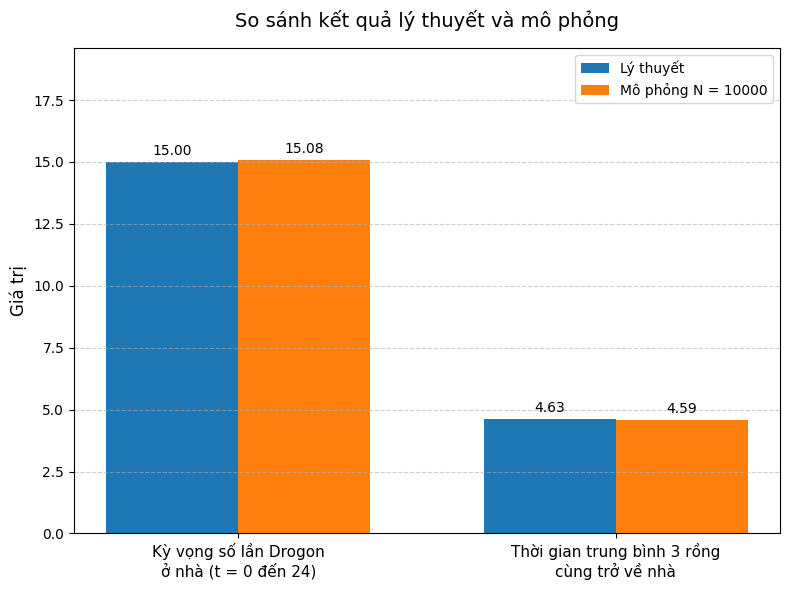

In [5]:
# --- 1. CÁC HÀM TIỆN ÍCH THỦ CÔNG CHO MÔ PHỎNG ---

def custom_random_choice(probabilities):
    """
    Hàm chọn trạng thái dựa trên một phân phối xác suất rời rạc.

    Tham số:
    - probabilities: danh sách xác suất của các trạng thái.

    Kết quả:
    - Trả về chỉ số trạng thái được chọn.
    """
    r = np.random.rand()
    cum_prob = 0.0

    for i, p in enumerate(probabilities):
        cum_prob += p
        if r < cum_prob:
            return i

    # Tránh lỗi do sai số làm tròn số thực
    return len(probabilities) - 1


def get_next_state(current_state, transition_matrix):
    """
    Hàm lấy trạng thái tiếp theo dựa vào trạng thái hiện tại và ma trận chuyển.

    Lưu ý:
    Trong đồ án, ma trận chuyển được dùng theo quy ước cột:
        P[i][j] = P(X_{t+1} = i | X_t = j)

    Vì vậy, nếu trạng thái hiện tại là current_state = j,
    ta lấy cột j của ma trận P làm phân phối xác suất cho trạng thái tiếp theo.
    """
    probabilities = [
        transition_matrix[next_state][current_state]
        for next_state in range(len(transition_matrix))
    ]

    return custom_random_choice(probabilities)


# --- 2. CÁC HÀM MÔ PHỎNG CHÍNH ---

def simulate_drogon(P, s, num_trials):
    """
    Mô phỏng số lần trung bình Drogon ở nhà trong các thời điểm 0, 1, ..., 24.

    Tham số:
    - P: ma trận chuyển trạng thái theo quy ước cột.
    - s: phân phối dừng.
    - num_trials: số lần mô phỏng độc lập.

    Kết quả:
    - Số lần trung bình Drogon ở nhà trong 25 thời điểm từ 0 đến 24.
    """
    total_home = 0

    for _ in range(num_trials):
        # Drogon xuất phát ngẫu nhiên theo phân phối dừng s
        state = custom_random_choice(s)

        # Tính cả thời điểm t = 0
        if state == 0:
            total_home += 1

        # Mô phỏng các thời điểm t = 1, 2, ..., 24
        for _ in range(24):
            state = get_next_state(state, P)

            if state == 0:
                total_home += 1

    return total_home / num_trials


def simulate_three_dragons(P, num_trials, max_time=100000):
    """
    Mô phỏng thời gian trung bình để cả ba con rồng cùng trở về nhà lần nữa.

    Tham số:
    - P: ma trận chuyển trạng thái theo quy ước cột.
    - num_trials: số lần mô phỏng độc lập.
    - max_time: giới hạn số bước mô phỏng để tránh vòng lặp quá dài.

    Kết quả:
    - Thời gian trung bình để cả ba con rồng cùng trở về nhà lần nữa.
    """
    total_time = 0
    successful_trials = 0

    for _ in range(num_trials):
        # Cả 3 bắt đầu ở nhà tại thời điểm 0
        x, y, z = 0, 0, 0

        for t in range(1, max_time + 1):
            # Ba con rồng di chuyển độc lập, nhưng có cùng ma trận chuyển P
            x = get_next_state(x, P)
            y = get_next_state(y, P)
            z = get_next_state(z, P)

            # Cả ba cùng trở về nhà lần nữa
            if x == 0 and y == 0 and z == 0:
                total_time += t
                successful_trials += 1
                break

    return total_time / successful_trials


# --- 3. THIẾT LẬP MỘT VÍ DỤ CỤ THỂ ĐỂ MÔ PHỎNG ---

# Ma trận chuyển theo quy ước cột của đề:
# Cột 0: từ Nhà (0) -> Nhà (0) với 0.8, Khác (1) với 0.2
# Cột 1: từ Khác (1) -> Nhà (0) với 0.3, Khác (1) với 0.7
P_sim = [
    [0.8, 0.3],
    [0.2, 0.7]
]

# Phân phối dừng tương ứng với P_sim:
# s = [0.6, 0.4]^T
s_sim = [0.6, 0.4]
s0 = s_sim[0]


# --- 4. THỰC THI VÀ TRỰC QUAN HÓA ---

N_trials = 10000

sim_drogon_visits = simulate_drogon(P_sim, s_sim, N_trials)
sim_return_time = simulate_three_dragons(P_sim, N_trials)

# Kết quả lý thuyết
theo_drogon_visits = 25 * s0
theo_return_time = 1 / (s0 ** 3)

print("Kết quả lý thuyết:")
print(f"- Kỳ vọng số lần Drogon ở nhà từ t = 0 đến t = 24: {theo_drogon_visits:.5f}")
print(f"- Thời gian kỳ vọng để cả ba rồng cùng trở về nhà lần nữa: {theo_return_time:.5f}")

print("\nKết quả mô phỏng:")
print(f"- Số lần trung bình Drogon ở nhà từ t = 0 đến t = 24: {sim_drogon_visits:.5f}")
print(f"- Thời gian trung bình để cả ba rồng cùng trở về nhà lần nữa: {sim_return_time:.5f}")


# --- 5. VẼ BIỂU ĐỒ SO SÁNH ---

labels = [
    'Kỳ vọng số lần Drogon\nở nhà (t = 0 đến 24)',
    'Thời gian trung bình 3 rồng\ncùng trở về nhà'
]

theory_vals = [theo_drogon_visits, theo_return_time]
sim_vals = [sim_drogon_visits, sim_return_time]

x = [0, 1]
width = 0.35

fig, ax = plt.subplots(figsize=(8, 6))

rects1 = ax.bar(
    [i - width / 2 for i in x],
    theory_vals,
    width,
    label='Lý thuyết'
)

rects2 = ax.bar(
    [i + width / 2 for i in x],
    sim_vals,
    width,
    label=f'Mô phỏng N = {N_trials}'
)

ax.set_ylabel('Giá trị', fontsize=12)
ax.set_title('So sánh kết quả lý thuyết và mô phỏng', pad=15, fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.legend()

ax.bar_label(rects1, fmt='%.2f', padding=3)
ax.bar_label(rects2, fmt='%.2f', padding=3)

plt.ylim(0, max(max(theory_vals), max(sim_vals)) * 1.3)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Tổng hợp kết quả và so sánh Câu 2d:**

Quan sát biểu đồ cột ghép ở trên, ta có thể so sánh hai nhóm kết quả: giá trị lý thuyết và giá trị thu được từ mô phỏng với $10{,}000$ lần lặp độc lập.

- **Đối với số lần Drogon ở nhà:** Kết quả mô phỏng gần với giá trị lý thuyết:

$$
E[N_0] = 25s_0 = 25 \times 0.6 = 15
$$

Điều này phù hợp với kết quả ở Câu 2a, vì Drogon bắt đầu theo phân phối dừng $s$, nên tại mỗi thời điểm xác suất Drogon ở nhà đều bằng $s_0$.

- **Đối với thời gian để cả ba con rồng cùng trở về nhà lần nữa:** Kết quả mô phỏng cũng gần với giá trị lý thuyết:

$$
E[T^+_{(0,0,0)}]
=
\frac{1}{s_0^3}
=
\frac{1}{0.6^3}
\approx 4.63
$$

Kết quả này phù hợp với công thức thời gian hồi quy trung bình, vì xác suất dừng của trạng thái cả ba con rồng cùng ở nhà là $s_0^3$.

**Nhận xét chung:** Kết quả mô phỏng cho thấy sự phù hợp với các giá trị lý thuyết đã tính ở Câu 2a và Câu 2c. Sự chênh lệch nhỏ giữa kết quả mô phỏng và kết quả lý thuyết là do chương trình sử dụng số ngẫu nhiên để sinh các bước chuyển trạng thái, nên mỗi lần chạy có thể cho ra kết quả hơi khác nhau. Tuy nhiên, khi số lần lặp đủ lớn, theo quy luật số lớn, giá trị trung bình mô phỏng sẽ dao động quanh và tiến gần đến giá trị kỳ vọng lý thuyết.

Do đó, kết quả mô phỏng góp phần xác nhận tính hợp lý của các lập luận toán học đã trình bày.